# Mexico City GP 2026: Winner Model

**Goal:** estimate each driver's probability of winning the 2026 Mexico City Grand Prix (Round 19, 1 Nov 2026).

**Plan**
1. Load the driver-by-race feature table (built by `src/build_features.py`).
2. Define how to score a model fairly: race-level metrics + a walk-forward backtest.
3. Set simple rule-based baselines the model has to beat.
4. Compare six model families, then tune how much **recent seasons and the 2026 rules era** should count.
5. Tune the most promising models, test whether more features help, try an ensemble.
6. Confirm the chosen model **once** on held-out seasons 2025-2026.
7. Train on everything and predict Mexico 2026.

Two prediction modes run side by side:
- **pre_weekend**: form, team strength, circuit history (available now).
- **post_quali**: adds grid and qualifying pace (run again after Saturday's qualifying).

## 1. Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from itertools import combinations

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

In [3]:
sys.path.insert(0, "src")
from build_features import PRE_WEEKEND, WEEKEND, NEW_REG_SEASONS, TARGET_SEASON, TARGET_ROUND
from race_models import RaceSoftmax, RaceWinModel, recency_weights

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)

In [4]:
VAL_SEASONS = [2021, 2022, 2023, 2024]   # used for every model decision
TEST_SEASONS = [2025, 2026]              # touched once, at the very end
RETRAIN_EVERY = 3                        # races between refits during validation
SEED = 0

MODELS_DIR = Path("models")
PRED_DIR = Path("data/predictions")
MODELS_DIR.mkdir(exist_ok=True)
PRED_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a",
          "muted": "#b9b8b2", "ink": "#52514e"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": COLORS["ink"],
    "xtick.color": COLORS["ink"], "ytick.color": COLORS["ink"],
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
})

## 2. Load the feature table

One row per driver per race, 2014-2026. Every feature only uses information from **before** that race.
Rows for the upcoming Mexico race have an empty `win` column. That is what we predict.

In [6]:
features = pd.read_csv("data/processed/features.csv", parse_dates=["date"])

done = features[features.win.notna()].reset_index(drop=True)      # races already run
upcoming = features[features.win.isna()].reset_index(drop=True)   # Mexico 2026 entry list

print(f"{len(done):,} driver-race rows from {done.race_key.nunique()} races")
print(f"{len(upcoming)} drivers to predict for {upcoming.race_name.iat[0]} {upcoming.season.iat[0]}")

5,501 driver-race rows from 270 races
22 drivers to predict for Mexico City Grand Prix 2026


In [7]:
done.groupby("season").agg(races=("race_key", "nunique"), rows=("win", "size")).T

season,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
races,19,19,21,20,21,21,17,22,22,22,24,24,18
rows,407,378,462,400,420,420,340,440,440,440,479,479,396


In [8]:
win_rate = done.win.mean()
print(f"Win rate per row: {win_rate:.1%}, about 1 winner per {1 / win_rate:.0f} rows")

Win rate per row: 4.9%, about 1 winner per 20 rows


## 3. Feature sets

- `pre_weekend`: everything known before the cars run (form, team strength, Elo, circuit history, context).
- `post_quali`: the same plus grid slot, qualifying position/gap, grid penalty, teammate gap.
- `pre_weekend_v1`: the first-stage features **without** this stage's additions, to check whether the new features actually help.

New this stage: short-term momentum (last 2-3 races, captures Red Bull's late-2026 surge),
season-only averages (reset every year, which matters after a rule change), race pace (fastest-lap rank),
racecraft (positions gained), teammate points share, last year's constructors' rank, and circuit character (winner's average grid, overtaking).

In [9]:
NEW_THIS_STAGE = [
    "drv_last2_avg_finish", "drv_last3_avg_points", "drv_last3_avg_quali_pos", "drv_wins_last5",
    "drv_season_avg_finish", "drv_season_avg_quali_gap", "drv_season_win_rate", "drv_form_trend",
    "drv_ewm_fastest_lap_rank", "drv_ewm_positions_gained", "drv_team_pts_share",
    "team_last2_points", "team_last2_best_finish", "team_last3_quali_gap", "team_season_avg_points",
    "team_season_avg_quali_gap", "team_form_trend", "team_prev_season_rank",
    "circuit_winner_avg_grid", "circuit_overtaking", "races_into_era",
    "drv_last3_avg_points_rank", "team_last2_points_rank", "drv_season_avg_quali_gap_rank",
    "team_season_avg_quali_gap_rank", "drv_ewm_fastest_lap_rank_rank",
]

In [10]:
FEATURE_SETS = {
    "pre_weekend": PRE_WEEKEND,
    "post_quali": PRE_WEEKEND + WEEKEND,
    "pre_weekend_v1": [c for c in PRE_WEEKEND if c not in NEW_THIS_STAGE],
}
for name, cols in FEATURE_SETS.items():
    print(f"{name:15s} {len(cols)} features")

pre_weekend     70 features
post_quali      77 features
pre_weekend_v1  44 features


## 4. How we score a model

Plain accuracy is useless here: predicting "nobody wins" is 95% accurate. Instead, each race is scored as a whole,
using probabilities normalised so they sum to 1 across the field:

| Metric | Meaning | Better |
|---|---|---|
| `log_loss` | mean of -log P(actual winner). **Main metric**: rewards confident *and* correct | lower |
| `top1_acc` | share of races where our favourite won | higher |
| `top3_acc` | share of races where the winner was in our top 3 | higher |
| `winner_prob` | average probability we gave the actual winner | higher |
| `brier` | squared error summed over the field, averaged per race | lower |

In [11]:
def race_metrics(pred):
    """Score a prediction frame with columns race_key, win, prob."""
    rank = pred.groupby("race_key").prob.rank(ascending=False, method="first")
    is_winner = pred.win == 1
    winner_prob = pred.prob[is_winner].clip(1e-6)
    return pd.Series({
        "races": pred.race_key.nunique(),
        "log_loss": -np.log(winner_prob).mean(),
        "top1_acc": (rank[is_winner] == 1).mean(),
        "top3_acc": (rank[is_winner] <= 3).mean(),
        "winner_prob": winner_prob.mean(),
        "brier": ((pred.prob - pred.win) ** 2).groupby(pred.race_key).sum().mean(),
    })

### Walk-forward backtest

To mimic real use, a model only ever sees races that happened **before** the race it predicts.
For each validation season we refit every few races on all earlier data, so in-season form (e.g. 2026) enters training as the season goes on.

Training rows can be **weighted**:
- `half_life`: a season's weight halves every *n* seasons back (`None` = all seasons equal).
- `era_boost`: extra weight for rows from the current regulation era (2014 / 2017 / 2022 / 2026 resets).

In [12]:
def era_start(season):
    """First season of the regulation era that `season` belongs to."""
    return max(s for s in NEW_REG_SEASONS if s <= season)


def weights_for(train, season, half_life=None, era_boost=1.0):
    """Sample weights for the training rows when predicting `season`."""
    return recency_weights(train.season, season, half_life, era_boost, era_start(season))

In [13]:
KEEP = ["race_key", "season", "round", "race_name", "circuit_id", "driver_id",
        "driver_code", "team", "win", "position"]


def walk_forward(make_model, seasons, retrain_every=RETRAIN_EVERY, **weighting):
    """Predict every race in `seasons`, training only on races run before it."""
    preds = []
    for season in seasons:
        rounds = sorted(done.loc[done.season == season, "round"].unique())
        for i in range(0, len(rounds), retrain_every):
            block = done[(done.season == season) & done["round"].isin(rounds[i:i + retrain_every])]
            train = done[done.date < block.date.min()]
            model = make_model().fit(train, sample_weight=weights_for(train, season, **weighting))
            preds.append(block[KEEP].assign(prob=model.predict(block)))
    return pd.concat(preds, ignore_index=True)

## 5. Baselines: simple rules

Things a fan might do without a model. Their "probabilities" are just their ranking, so only hit rates are comparable.
A no-information guess (every driver equally likely) gives the log-loss reference.

In [14]:
def rule_based(score_col, higher_is_better, seasons):
    """Rank drivers in each race by a single column."""
    d = done[done.season.isin(seasons)].copy()
    score = d[score_col] if higher_is_better else -d[score_col]
    rank = score.fillna(score.min() - 1).groupby(d.race_key).rank(ascending=False, method="first")
    d["prob"] = 1 / rank ** 2   # only the ordering matters
    d["prob"] /= d.groupby("race_key").prob.transform("sum")
    return d

In [15]:
RULES = {
    "Championship leader": ("drv_season_pts", True),
    "Best recent points (EWM)": ("drv_ewm_points", True),
    "Highest driver Elo": ("drv_elo", True),
    "Pole sitter (post-quali)": ("grid_pos", False),
}
baselines = pd.DataFrame({
    name: race_metrics(rule_based(col, hi, VAL_SEASONS))[["top1_acc", "top3_acc"]]
    for name, (col, hi) in RULES.items()
}).T
baselines

,top1_acc,top3_acc
Championship leader,0.556,0.811
Best recent points (EWM),0.544,0.778
Highest driver Elo,0.500,0.711
Pole sitter (post-quali),0.511,0.833


In [16]:
val_rows = done[done.season.isin(VAL_SEASONS)]
uniform_log_loss = np.log(val_rows.groupby("race_key").size()).mean()
print(f"No-information log loss (equal chances): {uniform_log_loss:.3f}")

No-information log loss (equal chances): 2.995


## 6. Candidate models

| Model | Idea |
|---|---|
| **Race softmax** | conditional logit: a linear score per driver, softmax across the field. Built for "exactly one winner per race" |
| **Logistic regression** | linear P(win) per driver, normalised per race afterwards |
| **Random forest** | many decorrelated trees, robust to noisy features |
| **HistGradientBoosting** | scikit-learn's histogram boosting |
| **LightGBM / XGBoost** | gradient-boosted trees, strong on tabular data and good at interactions (e.g. *grid x circuit*) |

Each factory returns a fresh, unfitted estimator. `RaceWinModel` (in `src/race_models.py`) normalises probabilities within each race.

In [17]:
def softmax(C=0.1):
    return RaceSoftmax(C=C)


def logreg(C=0.1):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=C, max_iter=5000))


def random_forest(min_samples_leaf=10):
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=400, min_samples_leaf=min_samples_leaf,
                                                max_features="sqrt", n_jobs=-1, random_state=SEED))

In [18]:
def hist_gb(learning_rate=0.05, max_leaf_nodes=15):
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=learning_rate,
                                          max_leaf_nodes=max_leaf_nodes, min_samples_leaf=40,
                                          l2_regularization=1.0, random_state=SEED)


def lgbm(learning_rate=0.03, num_leaves=15):
    return LGBMClassifier(n_estimators=300, learning_rate=learning_rate, num_leaves=num_leaves,
                          min_child_samples=40, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.7, reg_lambda=1.0, verbose=-1, random_state=SEED)


def xgb(learning_rate=0.03, max_depth=4):
    return XGBClassifier(n_estimators=300, learning_rate=learning_rate, max_depth=max_depth,
                         min_child_weight=5, subsample=0.8, colsample_bytree=0.7,
                         reg_lambda=1.0, n_jobs=4, random_state=SEED)

In [19]:
CANDIDATES = {
    "Race softmax": softmax,
    "Logistic regression": logreg,
    "Random forest": random_forest,
    "HistGradientBoosting": hist_gb,
    "LightGBM": lgbm,
    "XGBoost": xgb,
}


def single(name, features, **params):
    """Factory for a RaceWinModel wrapping one candidate."""
    return lambda: RaceWinModel({name: CANDIDATES[name](**params)}, features)

### 6.1 First comparison on validation (2021-2024)

Default settings, all seasons weighted equally, both modes.

In [20]:
val_preds, rows = {}, []
for mode in ["pre_weekend", "post_quali"]:
    for name in CANDIDATES:
        pred = walk_forward(single(name, FEATURE_SETS[mode]), VAL_SEASONS)
        val_preds[(mode, name)] = pred
        rows.append(race_metrics(pred).rename((mode, name)))
comparison = pd.DataFrame(rows)

In [21]:
comparison.loc["pre_weekend"].sort_values("log_loss")

,races,log_loss,top1_acc,top3_acc,winner_prob,brier
Random forest,90.0,1.487,0.511,0.811,0.326,0.640
XGBoost,90.0,1.517,0.489,0.744,0.364,0.646
Logistic regression,90.0,1.530,0.544,0.778,0.358,0.655
Race softmax,90.0,1.540,0.522,0.789,0.390,0.666
LightGBM,90.0,1.614,0.467,0.767,0.400,0.685
HistGradientBoosting,90.0,1.783,0.489,0.778,0.433,0.727


In [22]:
comparison.loc["post_quali"].sort_values("log_loss")

,races,log_loss,top1_acc,top3_acc,winner_prob,brier
XGBoost,90.0,1.259,0.567,0.867,0.427,0.581
Random forest,90.0,1.263,0.611,0.911,0.375,0.573
LightGBM,90.0,1.279,0.589,0.878,0.471,0.584
Logistic regression,90.0,1.344,0.500,0.856,0.399,0.612
Race softmax,90.0,1.346,0.489,0.867,0.445,0.614
HistGradientBoosting,90.0,1.459,0.578,0.878,0.500,0.624


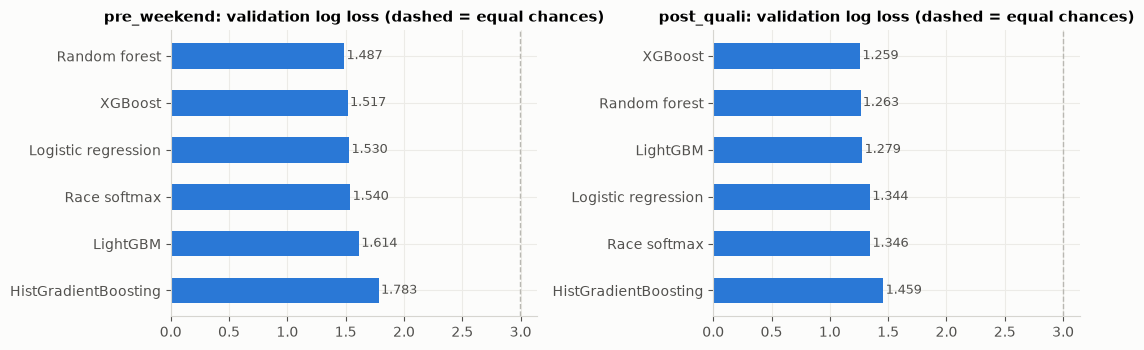

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, mode in zip(axes, ["pre_weekend", "post_quali"]):
    d = comparison.loc[mode].sort_values("log_loss", ascending=False)
    ax.barh(d.index, d.log_loss, color=COLORS["blue"], height=0.55)
    ax.axvline(uniform_log_loss, color=COLORS["muted"], ls="--", lw=1)
    ax.set_title(f"{mode}: validation log loss (dashed = equal chances)")
    for y, v in enumerate(d.log_loss):
        ax.text(v + 0.02, y, f"{v:.3f}", va="center", color=COLORS["ink"], fontsize=9)
plt.tight_layout()

### 6.2 How much should recent seasons and the current rules era count?

This tests the main domain question: **rules change, so older seasons may mislead**.
In 2026 Mercedes/Antonelli dominate the new rules while 2025 was a McLaren year. Weighting decides how much the model should trust each.
We try it on the three best models **of each mode**, because predicting before the weekend and after qualifying are different problems.

In [24]:
MODES = ["pre_weekend", "post_quali"]
top_models = {mode: comparison.loc[mode].sort_values("log_loss").index[:3].tolist() for mode in MODES}
WEIGHTINGS = [{"half_life": h, "era_boost": b} for h in (None, 4, 2) for b in (1, 3)]
top_models

{'pre_weekend': ['Random forest', 'XGBoost', 'Logistic regression'],
 'post_quali': ['XGBoost', 'Random forest', 'LightGBM']}

In [25]:
rows = []
for mode in MODES:
    for name in top_models[mode]:
        for w in WEIGHTINGS:
            pred = walk_forward(single(name, FEATURE_SETS[mode]), VAL_SEASONS, **w)
            rows.append({"mode": mode, "model": name, "weighting": w,
                         "half_life": str(w["half_life"]), "era_boost": w["era_boost"],
                         **race_metrics(pred)})
weighting_results = pd.DataFrame(rows)

In [26]:
def weighting_table(mode):
    d = weighting_results[weighting_results["mode"] == mode]
    return d.pivot_table(index=["half_life", "era_boost"], columns="model", values="log_loss")


weighting_table("pre_weekend")

model                Logistic regression  Random forest  XGBoost
half_life era_boost                                             
2         1                        1.502          1.495    1.454
          3                        1.549          1.533    1.606
4         1                        1.503          1.488    1.481
          3                        1.541          1.522    1.584
None      1                        1.530          1.487    1.517
          3                        1.550          1.487    1.554

In [27]:
weighting_table("post_quali")

model                LightGBM  Random forest  XGBoost
half_life era_boost                                  
2         1             1.285          1.272    1.218
          3             1.365          1.292    1.308
4         1             1.263          1.268    1.215
          3             1.374          1.291    1.283
None      1             1.279          1.263    1.259
          3             1.364          1.265    1.294

In [28]:
BEST_WEIGHTING = {mode: {} for mode in MODES}
for i in weighting_results.groupby(["mode", "model"]).log_loss.idxmin():
    row = weighting_results.loc[i]
    BEST_WEIGHTING[row["mode"]][row.model] = row.weighting
BEST_WEIGHTING

{'pre_weekend': {'Logistic regression': {'half_life': 2, 'era_boost': 1},
  'Random forest': {'half_life': None, 'era_boost': 1},
  'XGBoost': {'half_life': 2, 'era_boost': 1}},
 'post_quali': {'LightGBM': {'half_life': 4, 'era_boost': 1},
  'Random forest': {'half_life': None, 'era_boost': 1},
  'XGBoost': {'half_life': 4, 'era_boost': 1}}}

### 6.3 Hyperparameter tuning

Small grids on purpose: with ~90 validation races, a big search would mostly fit noise.

In [29]:
GRIDS = {
    "Race softmax": [{"C": c} for c in (0.01, 0.03, 0.1, 0.3, 1.0)],
    "Logistic regression": [{"C": c} for c in (0.01, 0.03, 0.1, 0.3, 1.0)],
    "Random forest": [{"min_samples_leaf": m} for m in (5, 10, 20, 40)],
    "HistGradientBoosting": [{"learning_rate": lr, "max_leaf_nodes": n} for lr in (0.03, 0.06) for n in (7, 15)],
    "LightGBM": [{"learning_rate": lr, "num_leaves": n} for lr in (0.015, 0.03) for n in (7, 15)],
    "XGBoost": [{"learning_rate": lr, "max_depth": d} for lr in (0.015, 0.03) for d in (3, 5)],
}

In [30]:
rows = []
for mode in MODES:
    for name in top_models[mode]:
        for params in GRIDS[name]:
            pred = walk_forward(single(name, FEATURE_SETS[mode], **params),
                                VAL_SEASONS, **BEST_WEIGHTING[mode][name])
            rows.append({"mode": mode, "model": name, "params": params, **race_metrics(pred)})
tuning = pd.DataFrame(rows)

In [31]:
def best_per_model(results, mode):
    """Best row of each model within one mode, best first."""
    d = results[results["mode"] == mode]
    return d.loc[d.groupby("model").log_loss.idxmin()].drop(columns="mode").sort_values("log_loss")


best_per_model(tuning, "pre_weekend")

,model,params,races,log_loss,top1_acc,top3_acc,winner_prob,brier
6,XGBoost,"{'learning_rate': 0.03, 'max_depth': 3}",90.0,1.453,0.500,0.822,0.378,0.627
2,Random forest,{'min_samples_leaf': 20},90.0,1.475,0.522,0.800,0.325,0.638
9,Logistic regression,{'C': 0.03},90.0,1.486,0.522,0.767,0.352,0.639


In [32]:
best_per_model(tuning, "post_quali")

,model,params,races,log_loss,top1_acc,top3_acc,winner_prob,brier
16,XGBoost,"{'learning_rate': 0.03, 'max_depth': 5}",90.0,1.202,0.589,0.889,0.439,0.553
21,LightGBM,"{'learning_rate': 0.015, 'num_leaves': 7}",90.0,1.236,0.544,0.900,0.424,0.566
19,Random forest,{'min_samples_leaf': 20},90.0,1.263,0.600,0.889,0.370,0.574


In [33]:
BEST_PARAMS = {mode: dict(zip(best_per_model(tuning, mode).model, best_per_model(tuning, mode).params))
               for mode in MODES}
BEST_SINGLE = {mode: best_per_model(tuning, mode).model.iat[0] for mode in MODES}
BEST_SINGLE

{'pre_weekend': 'XGBoost', 'post_quali': 'XGBoost'}

### 6.4 Do more features actually help?

Same tuned pre-weekend model, three feature sets. More features is only better if the validation score agrees.

In [34]:
name = BEST_SINGLE["pre_weekend"]
rows = []
for fs in ["pre_weekend_v1", "pre_weekend", "post_quali"]:
    pred = walk_forward(single(name, FEATURE_SETS[fs], **BEST_PARAMS["pre_weekend"][name]),
                        VAL_SEASONS, **BEST_WEIGHTING["pre_weekend"][name])
    rows.append(race_metrics(pred).rename(f"{fs} ({len(FEATURE_SETS[fs])} feats)"))
print("Model:", name)
pd.DataFrame(rows)

Model: XGBoost


,races,log_loss,top1_acc,top3_acc,winner_prob,brier
pre_weekend_v1 (44 feats),90.0,1.504,0.489,0.778,0.373,0.640
pre_weekend (70 feats),90.0,1.453,0.500,0.822,0.378,0.627
post_quali (77 feats),90.0,1.223,0.622,0.900,0.438,0.557


### 6.5 Ensembles

Linear and tree models make different mistakes, so averaging them often beats either alone.
Each member keeps its tuned parameters and all are trained with the best single model's weighting.

In [35]:
def ensemble(names, features, params):
    """Factory for an averaged RaceWinModel of tuned candidates."""
    return lambda: RaceWinModel({n: CANDIDATES[n](**params[n]) for n in names}, features)


def ensemble_options(names):
    """Every pair of the top three, plus all three together."""
    return [list(pair) for pair in combinations(names, 2)] + [names]

In [36]:
rows = []
for mode in MODES:
    for names in ensemble_options(top_models[mode]):
        pred = walk_forward(ensemble(names, FEATURE_SETS[mode], BEST_PARAMS[mode]), VAL_SEASONS,
                            **BEST_WEIGHTING[mode][BEST_SINGLE[mode]])
        rows.append({"mode": mode, "model": " + ".join(names), "members": names, **race_metrics(pred)})
ensemble_results = pd.DataFrame(rows)

### 6.6 Pick the winner of each mode

All tuned single models and ensembles side by side, on validation only. The lowest log loss wins.

In [37]:
singles = tuning.loc[tuning.groupby(["mode", "model"]).log_loss.idxmin()]
singles = singles.assign(members=singles.model.map(lambda m: [m])).drop(columns="params")
final_board = pd.concat([singles, ensemble_results]).sort_values(["mode", "log_loss"])
final_board.drop(columns="members").set_index(["mode", "model"])

races  log_loss  \
mode        model                                                            
post_quali  XGBoost                                         90.0     1.202   
            XGBoost + Random forest                         90.0     1.208   
            XGBoost + Random forest + LightGBM              90.0     1.211   
            XGBoost + LightGBM                              90.0     1.214   
            Random forest + LightGBM                        90.0     1.227   
            LightGBM                                        90.0     1.236   
            Random forest                                   90.0     1.263   
pre_weekend XGBoost + Logistic regression                   90.0     1.445   
            Random forest + XGBoost + Logistic regression   90.0     1.452   
            Random forest + XGBoost                         90.0     1.452   
            XGBoost                                         90.0     1.453   
            Random forest + Logistic regression             90.0     1.472   
            Random forest                                   90.0     1.475   
            Logistic regression                             90.0     1.486   

                                                           top1_acc  top3_acc  \
mode        model                                                               
post_quali  XGBoost                                           0.589     0.889   
            XGBoost + Random forest                           0.589     0.900   
            XGBoost + Random forest + LightGBM                0.567     0.911   
            XGBoost + LightGBM                                0.578     0.889   
            Random forest + LightGBM                          0.567     0.900   
            LightGBM                                          0.544     0.900   
            Random forest                                     0.600     0.889   
pre_weekend XGBoost + Logistic regression                     0.511     0.800   
            Random forest + XGBoost + Logistic regression     0.500     0.800   
            Random forest + XGBoost                           0.489     0.800   
            XGBoost                                           0.500     0.822   
            Random forest + Logistic regression               0.511     0.778   
            Random forest                                     0.522     0.800   
            Logistic regression                               0.522     0.767   

                                                           winner_prob  brier  
mode        model                                                              
post_quali  XGBoost                                              0.439  0.553  
            XGBoost + Random forest                              0.410  0.554  
            XGBoost + Random forest + LightGBM                   0.414  0.556  
            XGBoost + LightGBM                                   0.431  0.557  
            Random forest + LightGBM                             0.402  0.563  
            LightGBM                                             0.424  0.566  
            Random forest                                        0.370  0.574  
pre_weekend XGBoost + Logistic regression                        0.365  0.627  
            Random forest + XGBoost + Logistic regression        0.360  0.627  
            Random forest + XGBoost                              0.364  0.625  
            XGBoost                                              0.378  0.627  
            Random forest + Logistic regression                  0.351  0.633  
            Random forest                                        0.325  0.638  
            Logistic regression                                  0.352  0.639

In [38]:
CHOSEN = {}
for mode in MODES:
    best = final_board[final_board["mode"] == mode].iloc[0]
    CHOSEN[mode] = {
        "members": best.members,
        "params": {n: BEST_PARAMS[mode][n] for n in best.members},
        "weighting": BEST_WEIGHTING[mode][BEST_SINGLE[mode]],
        "validation": best.drop(["mode", "model", "members"]).astype(float).round(3).to_dict(),
    }
CHOSEN

{'pre_weekend': {'members': ['XGBoost', 'Logistic regression'],
  'params': {'XGBoost': {'learning_rate': 0.03, 'max_depth': 3},
   'Logistic regression': {'C': 0.03}},
  'weighting': {'half_life': 2, 'era_boost': 1},
  'validation': {'races': 90.0,
   'log_loss': 1.445,
   'top1_acc': 0.511,
   'top3_acc': 0.8,
   'winner_prob': 0.365,
   'brier': 0.627}},
 'post_quali': {'members': ['XGBoost'],
  'params': {'XGBoost': {'learning_rate': 0.03, 'max_depth': 5}},
  'weighting': {'half_life': 4, 'era_boost': 1},
  'validation': {'races': 90.0,
   'log_loss': 1.202,
   'top1_acc': 0.589,
   'top3_acc': 0.889,
   'winner_prob': 0.439,
   'brier': 0.553}}}

In [39]:
def make_chosen(mode):
    """Factory for the selected model of a mode."""
    c = CHOSEN[mode]
    return lambda: RaceWinModel({n: CANDIDATES[n](**c["params"][n]) for n in c["members"]},
                                FEATURE_SETS[mode])

## 7. Final test: 2025 and 2026 (never used for decisions)

Now the model is retrained **before every race**, exactly as it will be used live.
2026 is the hardest test: a new rules era, where last year's form is least reliable.

In [40]:
test_preds = {mode: walk_forward(make_chosen(mode), TEST_SEASONS, retrain_every=1,
                                 **CHOSEN[mode]["weighting"])
              for mode in MODES}

In [41]:
test_scores = pd.concat({mode: pred.groupby("season").apply(race_metrics)
                         for mode, pred in test_preds.items()})
test_scores

races  log_loss  top1_acc  top3_acc  winner_prob  brier
            season                                                         
pre_weekend 2025     24.0     1.586     0.375     0.875        0.249  0.768
            2026     18.0     1.705     0.444     0.778        0.249  0.763
post_quali  2025     24.0     1.043     0.625     1.000        0.400  0.579
            2026     18.0     0.812     0.722     0.944        0.508  0.391

### Model vs. the best simple rule

Before the weekend the natural rule is "back the championship leader"; after qualifying it is "back the pole-sitter".
Only the model gives usable probabilities, but its favourite should also be compared with the rule's pick.

In [42]:
RULE_FOR_MODE = {"pre_weekend": "Championship leader", "post_quali": "Pole sitter (post-quali)"}
rows = []
for mode in MODES:
    col, hi = RULES[RULE_FOR_MODE[mode]]
    rule_pred = rule_based(col, hi, TEST_SEASONS)
    for season in TEST_SEASONS:
        m = race_metrics(test_preds[mode][test_preds[mode].season == season])
        r = race_metrics(rule_pred[rule_pred.season == season])
        rows.append({"mode": mode, "season": season, "rule": RULE_FOR_MODE[mode],
                     "model_top1": m.top1_acc, "rule_top1": r.top1_acc,
                     "model_top3": m.top3_acc, "rule_top3": r.top3_acc})
pd.DataFrame(rows).set_index(["mode", "season"])

rule  model_top1  rule_top1  \
mode        season                                                    
pre_weekend 2025         Championship leader       0.375      0.250   
            2026         Championship leader       0.444      0.444   
post_quali  2025    Pole sitter (post-quali)       0.625      0.667   
            2026    Pole sitter (post-quali)       0.722      0.722   

                    model_top3  rule_top3  
mode        season                         
pre_weekend 2025         0.875      0.875  
            2026         0.778      0.722  
post_quali  2025         1.000      0.958  
            2026         0.944      0.944

## 8. 2026 race by race (pre-weekend mode)

Who the model made favourite before each race, and how much it believed in the eventual winner.

In [43]:
def race_table(pred):
    """One line per race: our favourite vs. the actual winner."""
    rows = []
    for key, race in pred.groupby("race_key"):
        race = race.sort_values("prob", ascending=False).reset_index(drop=True)
        winner = race.index[race.win == 1][0]
        rows.append({"season": race.season.iat[0], "round": race["round"].iat[0], "race": race.race_name.iat[0].replace(" Grand Prix", ""),
                     "favourite": race.driver_code.iat[0], "fav_prob": race.prob.iat[0],
                     "winner": race.driver_code.iat[winner], "winner_prob": race.prob.iat[winner],
                     "winner_rank": winner + 1})
    return pd.DataFrame(rows).set_index("round")

In [44]:
season_2026 = race_table(test_preds["pre_weekend"].query("season == 2026"))
season_2026

,season,race,favourite,fav_prob,winner,winner_prob,winner_rank
round,,,,,,,
1,2026,Australian,VER,0.373,RUS,0.078,4
2,2026,Chinese,RUS,0.284,ANT,0.077,5
3,2026,Japanese,ANT,0.386,ANT,0.386,1
4,2026,Miami,ANT,0.452,ANT,0.452,1
5,2026,Canadian,ANT,0.450,ANT,0.450,1
6,2026,Monaco,ANT,0.623,ANT,0.623,1
7,2026,Barcelona,ANT,0.664,HAM,0.117,2
8,2026,Austrian,ANT,0.397,RUS,0.100,3
9,2026,British,ANT,0.300,LEC,0.029,6


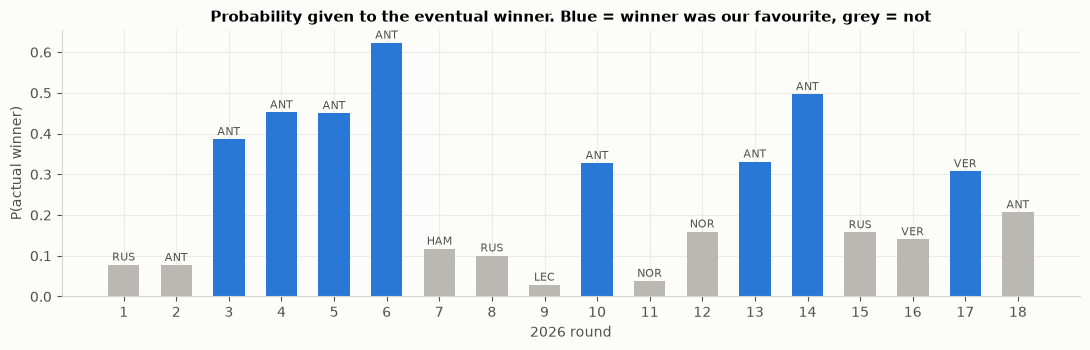

In [45]:
fig, ax = plt.subplots(figsize=(11, 3.6))
hit = season_2026.winner_rank == 1
ax.bar(season_2026.index, season_2026.winner_prob, width=0.6,
       color=np.where(hit, COLORS["blue"], COLORS["muted"]))
for r, row in season_2026.iterrows():
    ax.text(r, row.winner_prob + 0.01, row.winner, ha="center", fontsize=8, color=COLORS["ink"])
ax.set_xticks(season_2026.index)
ax.set_xlabel("2026 round")
ax.set_ylabel("P(actual winner)")
ax.set_title("Probability given to the eventual winner. Blue = winner was our favourite, grey = not")
plt.tight_layout()

The same season seen **after qualifying**:

In [46]:
season_2026_post = race_table(test_preds["post_quali"].query("season == 2026"))
season_2026_post

,season,race,favourite,fav_prob,winner,winner_prob,winner_rank
round,,,,,,,
1,2026,Australian,RUS,0.604,RUS,0.604,1
2,2026,Chinese,ANT,0.629,ANT,0.629,1
3,2026,Japanese,ANT,0.819,ANT,0.819,1
4,2026,Miami,ANT,0.722,ANT,0.722,1
5,2026,Canadian,RUS,0.534,ANT,0.194,2
6,2026,Monaco,ANT,0.682,ANT,0.682,1
7,2026,Barcelona,ANT,0.386,HAM,0.373,2
8,2026,Austrian,HAM,0.358,RUS,0.353,2
9,2026,British,ANT,0.679,LEC,0.053,4


## 9. How would it have done in Mexico?

Mexico races from the validation (2021-2024) and test (2025) backtests, chosen model, pre-weekend mode.

In [47]:
chosen_val = walk_forward(make_chosen("pre_weekend"), VAL_SEASONS, **CHOSEN["pre_weekend"]["weighting"])
history = pd.concat([chosen_val, test_preds["pre_weekend"]])
mexico_hist = history[history.circuit_id == "rodriguez"]
race_table(mexico_hist).set_index("season")

,race,favourite,fav_prob,winner,winner_prob,winner_rank
season,,,,,,
2021,Mexico City,HAM,0.458,VER,0.243,2
2022,Mexico City,VER,0.615,VER,0.615,1
2023,Mexico City,VER,0.788,VER,0.788,1
2024,Mexico City,NOR,0.349,SAI,0.075,5
2025,Mexico City,VER,0.337,NOR,0.218,3


In [48]:
top3 = (mexico_hist.sort_values("prob", ascending=False).groupby("season").head(3)
        .assign(pick=lambda d: d.driver_code + " " + (100 * d.prob).round(0).astype(int).astype(str) + "%")
        .groupby("season").pick.apply(" | ".join))
pd.DataFrame({"model top 3": top3,
              "actual winner": mexico_hist[mexico_hist.win == 1].set_index("season").driver_code})

,model top 3,actual winner
season,,
2021,HAM 46% | VER 24% | BOT 12%,VER
2022,VER 62% | PER 14% | LEC 9%,VER
2023,VER 79% | PER 3% | SAI 3%,VER
2024,NOR 35% | VER 19% | PIA 18%,SAI
2025,VER 34% | PIA 24% | NOR 22%,NOR


## 10. Calibration: do the probabilities mean what they say?

If the model says 30%, drivers in that bucket should win about 30% of the time.

In [49]:
calib = pd.concat(test_preds.values()).assign(
    bucket=lambda d: pd.cut(d.prob, [0, 0.05, 0.15, 0.3, 0.5, 1.0]))
calib_table = calib.groupby("bucket", observed=True).agg(
    predicted=("prob", "mean"), observed=("win", "mean"), drivers=("win", "size"))
calib_table

,predicted,observed,drivers
bucket,,,
"(0.0, 0.05]",0.005,0.002,1416
"(0.05, 0.15]",0.088,0.087,150
"(0.15, 0.3]",0.223,0.239,92
"(0.3, 0.5]",0.383,0.424,59
"(0.5, 1.0]",0.610,0.636,33


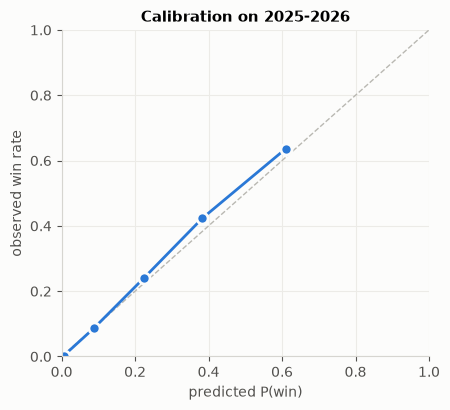

In [50]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=COLORS["muted"], ls="--", lw=1)
ax.plot(calib_table.predicted, calib_table.observed, color=COLORS["blue"], lw=2,
        marker="o", markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.set_xlabel("predicted P(win)")
ax.set_ylabel("observed win rate")
ax.set_title("Calibration on 2025-2026")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()

## 11. What drives the predictions?

**Permutation importance:** shuffle one feature and measure how much the test log loss gets worse.
Each mode's chosen model is trained on data up to 2024 and judged on 2025-2026.

In [51]:
def permutation_importance(mode):
    """Increase in 2025-26 log loss when each feature is shuffled."""
    train = done[done.season <= 2024]
    test = done[done.season.isin(TEST_SEASONS)]
    model = make_chosen(mode)().fit(train, sample_weight=weights_for(train, 2025, **CHOSEN[mode]["weighting"]))
    base = race_metrics(test[KEEP].assign(prob=model.predict(test))).log_loss
    rng = np.random.default_rng(SEED)
    out = {}
    for col in FEATURE_SETS[mode]:
        shuffled = test.assign(**{col: rng.permutation(test[col].to_numpy())})
        out[col] = race_metrics(shuffled[KEEP].assign(prob=model.predict(shuffled))).log_loss - base
    return pd.Series(out).sort_values(ascending=False)

In [52]:
importance = pd.DataFrame({mode: permutation_importance(mode) for mode in MODES})
importance.sort_values("pre_weekend", ascending=False).head(10)

,pre_weekend,post_quali
drv_elo_gap_to_best,0.084,8.325e-02
drv_career_win_rate,0.044,4.884e-02
drv_ewm_points,0.033,-7.821e-04
drv_age,0.029,2.292e-03
drv_ewm_quali_gap,0.027,5.810e-04
drv_season_avg_quali_gap,0.023,-6.325e-03
drv_season_avg_quali_gap_rank,0.020,6.776e-03
drv_ewm_fastest_lap_rank,0.017,3.631e-03
drv_season_pts_share,0.017,-1.704e-03
drv_ewm_quali_pos,0.016,-2.363e-03


In [53]:
importance.sort_values("post_quali", ascending=False).head(10)

,pre_weekend,post_quali
grid_pos,NaN,0.163
quali_gap_pct,NaN,0.135
quali_position,NaN,0.133
drv_elo_gap_to_best,0.084,0.083
drv_career_win_rate,0.044,0.049
team_ewm_points,0.005,0.026
team_ewm_best_finish,-0.002,0.016
drv_starts,-0.005,0.015
front_row,NaN,0.009
team_form_trend,0.003,0.009


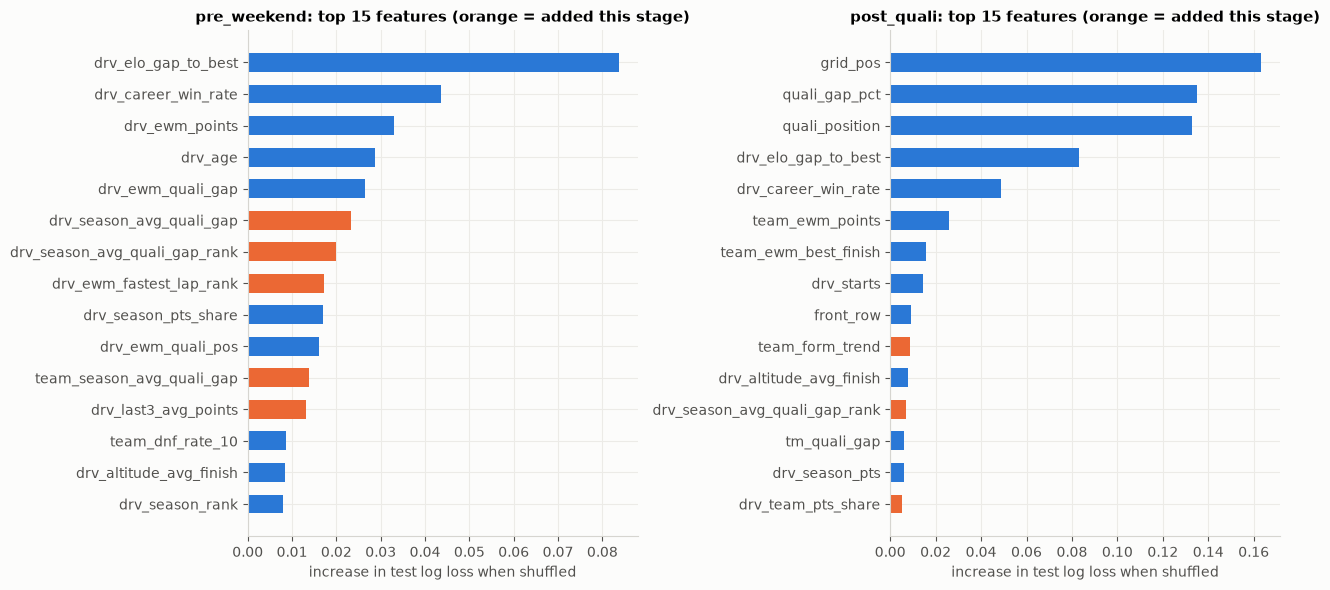

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, mode in zip(axes, MODES):
    top = importance[mode].sort_values(ascending=False).head(15)[::-1]
    is_new = top.index.isin(NEW_THIS_STAGE)
    ax.barh(top.index, top.values, color=np.where(is_new, COLORS["orange"], COLORS["blue"]), height=0.6)
    ax.set_title(f"{mode}: top 15 features (orange = added this stage)")
    ax.set_xlabel("increase in test log loss when shuffled")
plt.tight_layout()

## 12. Final model and the Mexico 2026 prediction

Train on **every** completed race (2014 to Austin 2026) with the chosen weighting, then predict the 22 entrants.

In [55]:
final_models = {
    mode: make_chosen(mode)().fit(done, sample_weight=weights_for(done, TARGET_SEASON, **CHOSEN[mode]["weighting"]))
    for mode in MODES
}

In [56]:
member_probs = final_models["pre_weekend"].predict_members(upcoming)
mexico = upcoming[["driver_code", "driver_id", "team"]].assign(
    win_prob=final_models["pre_weekend"].predict(upcoming),
    **{f"p_{name}": p for name, p in member_probs.items()},
).sort_values("win_prob", ascending=False).reset_index(drop=True)
mexico.index += 1
mexico.head(10).round(3)

,driver_code,driver_id,team,win_prob,p_XGBoost,p_Logistic regression
1,ANT,antonelli,mercedes,0.402,0.429,0.376
2,VER,max_verstappen,red_bull,0.216,0.187,0.244
3,LEC,leclerc,ferrari,0.111,0.104,0.119
4,HAM,hamilton,ferrari,0.090,0.096,0.084
5,HAD,hadjar,red_bull,0.051,0.069,0.032
6,NOR,norris,mclaren,0.046,0.047,0.046
7,RUS,russell,mercedes,0.046,0.033,0.059
8,PIA,piastri,mclaren,0.021,0.017,0.024
9,LAW,lawson,rb,0.004,0.002,0.007
10,LIN,arvid_lindblad,rb,0.003,0.002,0.004


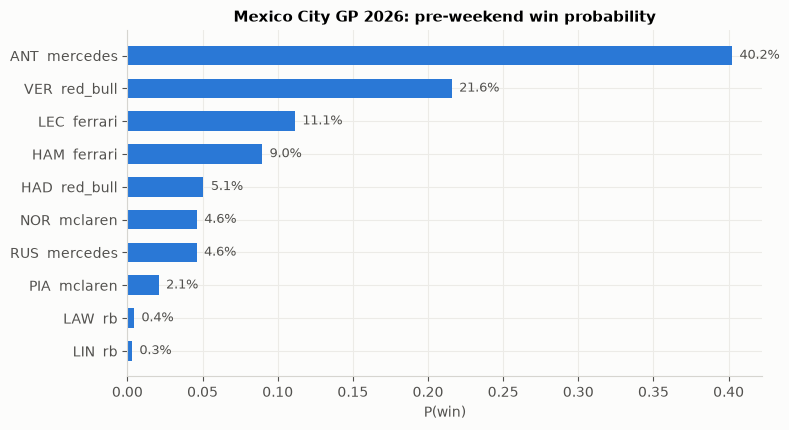

In [57]:
top10 = mexico.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(top10.driver_code + "  " + top10.team, top10.win_prob, color=COLORS["blue"], height=0.6)
for y, v in enumerate(top10.win_prob):
    ax.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=9, color=COLORS["ink"])
ax.set_xlabel("P(win)")
ax.set_title("Mexico City GP 2026: pre-weekend win probability")
plt.tight_layout()

### Save everything the dashboard will need

In [58]:
for mode, model in final_models.items():
    joblib.dump(model, MODELS_DIR / f"{mode}.joblib")

mexico.to_csv(PRED_DIR / "mexico_2026_pre_weekend.csv", index_label="rank")
season_2026.to_csv(PRED_DIR / "backtest_2026_pre_weekend.csv")
season_2026_post.to_csv(PRED_DIR / "backtest_2026_post_quali.csv")
pd.concat(test_preds, names=["mode"]).reset_index(level=0).to_csv(PRED_DIR / "backtest_test_seasons.csv", index=False)
importance.to_csv(PRED_DIR / "feature_importance.csv", index_label="feature")

In [59]:
model_card = {
    "chosen": CHOSEN,
    "feature_sets": {m: FEATURE_SETS[m] for m in MODES},
    "test": {f"{m}_{s}": v.to_dict() for (m, s), v in test_scores.iterrows()},
    "trained_through": done.race_key.max(),
}
(MODELS_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2, default=str))
print("Saved:", sorted(p.name for p in MODELS_DIR.iterdir()), sorted(p.name for p in PRED_DIR.iterdir()))

Saved: ['model_card.json', 'post_quali.joblib', 'pre_weekend.joblib'] ['backtest_2026_post_quali.csv', 'backtest_2026_pre_weekend.csv', 'backtest_test_seasons.csv', 'feature_importance.csv', 'mexico_2026_pre_weekend.csv']


## 13. Conclusions (run of 27 Oct 2026, data through the 2026 United States GP)

**Chosen models** (equal-chances log loss is about 3.0)

| Mode | Model | Training weights | Validation log loss | Test log loss 2025 / 2026 | Favourite won 2025 / 2026 | Winner in top 3 2025 / 2026 |
|---|---|---|---|---|---|---|
| pre_weekend | XGBoost (lr 0.03, depth 3) + logistic regression (C 0.03), averaged | half-life 2 seasons | 1.445 | 1.586 / 1.705 | 38% / 44% | 88% / 78% |
| post_quali | XGBoost (lr 0.03, depth 5) | half-life 4 seasons | 1.202 | 1.043 / 0.812 | 63% / 72% | 100% / 94% |

**What we learned**
- **Qualifying is the strongest signal.** After qualifying the winner was in the model's top 3 in 41 of 42 test races. Its favourite wins as often as "back the pole-sitter" (72% in 2026), but it adds probabilities (section 10).
- **Before the weekend, F1 is hard to call, but the model beats the simple rule.** Its favourite won 38% / 44% of races against 25% / 44% for "back the championship leader", and the winner was in its top 3 more often in 2026 (78% vs 72%).
- **More features helped.** Going from 44 to 70 features improved validation log loss from 1.504 to 1.453. Three of the top ten pre-weekend features are new: season qualifying gap, its rank, and race pace (fastest-lap rank).
- **Regulation changes.** Down-weighting old seasons helped: a half-life of 2 seasons before the weekend, 4 after qualifying. Extra weight on the current rules era *hurt* every model: the season-only and short-window features already capture the new order, and up-weighting a handful of races overfits. So "2026 is different" is handled by the features, not by the weights.
- **Momentum counts.** Verstappen is 2nd (21.6%) despite having fewer points than Russell, because Red Bull's last three races (two wins) push up the short-window features. In the backtest the model already made Verstappen favourite for Singapore and Austin.
- **Mexico backtest.** The favourite won 2 of the last 5 Mexico races and the winner was in the model's top 3 in 4 of 5. Sainz (2024, ranked 5th) was the miss.
- **Leakage check.** An earlier version of `team_circuit_best_finish` let a car see its teammate's finish from the same race. It was fixed and is covered by `tests/test_pipeline.py`, which scrambles a finished race's result and requires that race's features to stay identical. All numbers above are after the fix.

**Mexico City GP 2026, before the weekend:** Antonelli 40.2%, Verstappen 21.6%, Leclerc 11.1%, Hamilton 9.0%, Hadjar 5.1%.

**Next steps**
- After qualifying (Sat 31 Oct): `.venv/bin/python src/predict.py post_quali --refresh` (see README).
- Not used yet: practice long-run pace (FastF1) and weather (Mexico is almost always dry).
- The dashboard stage reads `models/*.joblib`, `models/model_card.json` and `data/predictions/*.csv`.